In [108]:
# relevant import

In [122]:
import importlib
import Diffusion
import LossFunctions
import ConsistencyModels
import  FlowMatching
from ConsistencyModels import ConsistencyModel
import dist_utils
import Optimization

importlib.reload(Diffusion)
importlib.reload(LossFunctions)
importlib.reload(ConsistencyModels)
importlib.reload(FlowMatching)
importlib.reload(dist_utils)
importlib.reload(Optimization)


<module 'Optimization' from 'C:\\Users\\orine\\PycharmProjects\\finalThesis\\Optimization.py'>

In [3]:
import matplotlib.pyplot as plt
import torch
import numpy as np

In [72]:
mu_list = [np.array([-5, 4]),
           np.array([5, -4]),
           np.array([3, 5]),np.array([-1, 5]), np.array([0, 0]), np.array([5, -1]),np.array([-5, -1]), np.array([2, 1]),np.array([1, -7])
           ]

point_l = [[int(p[1]), int(p[0])] for p in mu_list]

mu_list = [torch.tensor(p, dtype=torch.float64) for p in point_l]

# Convert Sigma_list to 3D covariance matrices
Sigma_list = [
    torch.tensor([[0.5,0.25],[0.12,0.2]], dtype=torch.float64)
] * len(mu_list)

# Mixture weights
alpha =torch.tensor( [1 / len(mu_list)] * len(mu_list),dtype=torch.float64)
# Generate samples
device = 'cpu'  # Change to 'cuda' if using a GPU
# X = dist_utils.generate_mog_samples(n_samples, mu_list, Sigma_list, alpha )


mog_means = [
    torch.tensor([5.0], dtype=torch.float64),
    # torch.tensor([-5.0], dtype=torch.float64),

]
mog_variances = [torch.tensor([.14], dtype=torch.float64),
     # torch.tensor([.25], dtype=torch.float64),
     ]
weights = torch.tensor([1.,
                        # .5
                        ], dtype=torch.float64)


In [73]:
X = dist_utils.generate_mog_samples(50_000, mu_list, Sigma_list, alpha).float().to(device)

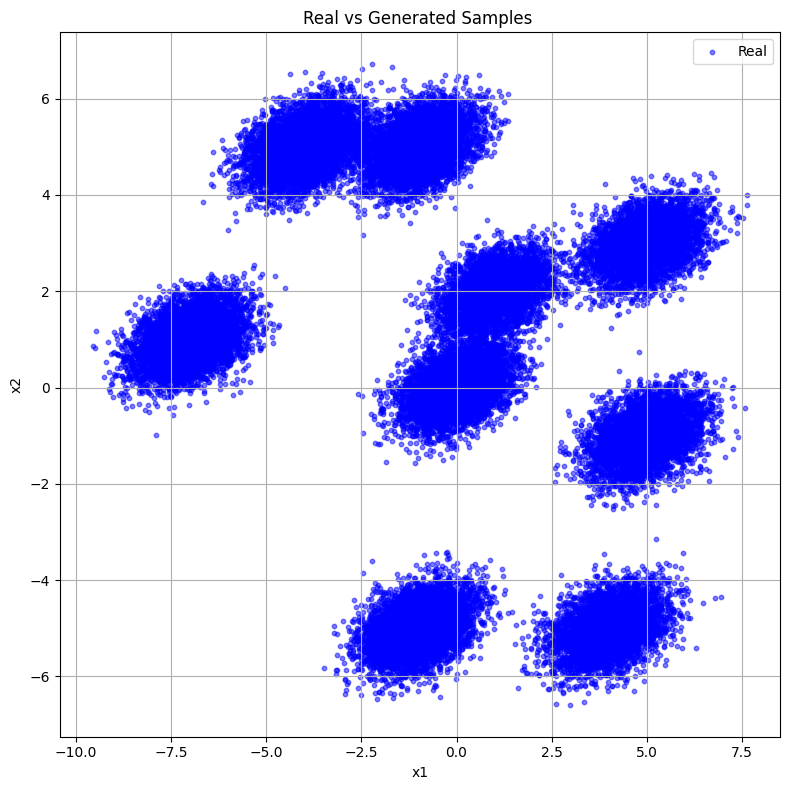

In [74]:
plt.figure(figsize=(8, 8))
plt.scatter(X[:, 0], X[:, 1], color="blue", alpha=0.5, label="Real", s=10)
plt.title(f"Real vs Generated Samples ")
plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## LGD

In [75]:
# better version
# init a model, train
nfeatures= X.shape[1]
model_cond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=True,condition_on=1)
losses = model_cond.train_model(X, nepochs=50, batch_size=3*2048,condition_on=1)

loss: 0.234457: 100%|██████████| 50/50 [02:11<00:00,  2.62s/it]


In [77]:
# init a model, train
X_for_cond_only=X[:,:model_cond.condition_on]
nfeatures= X_for_cond_only.shape[1]
model_uncond = Diffusion.DiffusionModel(nfeatures=nfeatures, nblocks=4, nunits=128, condition=False,)
losses = model_uncond.train_model(X_for_cond_only, nepochs=50, batch_size=3*2048,condition_on=1)

loss: 0.496129: 100%|██████████| 50/50 [01:31<00:00,  1.82s/it]


In [123]:
x_optim = Optimization.optimize_LGD(model_uncond, model_cond, mog_means, mog_variances, weights,mu_list, Sigma_list,alpha, nsamples=250, loss="MMD")

Step 1 | x_t: -4.354| mean_loss: 0.058: 100%|██████████| 99/99 [06:56<00:00,  4.21s/it] 


In [124]:
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)

tensor(0.1811, dtype=torch.float64)


## D-FLOW

In [125]:
input_dim = mog_means[0].shape[0]
y_dim = mu_list[0].shape[0] - input_dim
hidden_dim = 256
depth = 4


In [83]:

vf_y_cond_x = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=y_dim,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_y_cond_x.train_FM(lr=0.001, batch_size=1024, X=X, nepochs=50)


loss: 3.663257: 100%|██████████| 50/50 [04:31<00:00,  5.43s/it]


In [84]:
first_column_x=X[:,0].reshape(-1,1)#print()
vf_X = FlowMatching.FMModel(nfeatures=input_dim,
                                   condition_on=0,
                                   nunits=hidden_dim,
                                   nblocks=depth,
                                   device=device)
vf_X.train_FM(lr=0.001, batch_size=1024, X=first_column_x, nepochs=50)


loss: 6.004507: 100%|██████████| 50/50 [03:45<00:00,  4.50s/it]


In [126]:
x_optim,loss= Optimization.optimize_DFLOW(vf_y_cond_x, vf_X, device, mog_means, mog_variances, weights, max_iter=100,FLAG=True,n_sample=500)

x_0: [[-0.07264937]]|x_1: tensor([[-0.4737]], grad_fn=<SelectBackward0>)|loss: 2.75723622918235
x_0: [[-1.0726494]]|x_1: tensor([[-4.1402]], grad_fn=<SelectBackward0>)|loss: 0.029013023767480384
x_0: [[-1.2396134]]|x_1: tensor([[-4.7251]], grad_fn=<SelectBackward0>)|loss: 0.09310066491044822
x_0: [[-1.1639454]]|x_1: tensor([[-4.4490]], grad_fn=<SelectBackward0>)|loss: 0.03345003983854511
x_0: [[-1.0911192]]|x_1: tensor([[-4.2036]], grad_fn=<SelectBackward0>)|loss: 0.03451971207964277
x_0: [[-1.0748492]]|x_1: tensor([[-4.1478]], grad_fn=<SelectBackward0>)|loss: 0.0426129573549745
x_0: [[-1.0726771]]|x_1: tensor([[-4.1403]], grad_fn=<SelectBackward0>)|loss: 0.0567394888006687
x_0: [[-1.0726521]]|x_1: tensor([[-4.1402]], grad_fn=<SelectBackward0>)|loss: 0.057763904713195036
x_0: [[-1.0726494]]|x_1: tensor([[-4.1402]], grad_fn=<SelectBackward0>)|loss: 0.038550902717365165


In [127]:
print(x_optim)

tensor([[-4.1402]], grad_fn=<SelectBackward0>)


In [128]:
l1_distance = dist_utils.warpper_L1_distance(x_optim,mu_list, Sigma_list, alpha, mog_means, mog_variances, weights)
print(l1_distance)


tensor(0.0718, dtype=torch.float64, grad_fn=<MulBackward0>)
